# Single-Region Comprehensive Validation Pipeline
This notebook executes an end-to-end evaluation for a single calorimeter kinematic region ($E_T \times \eta$):
1. **Split Manifest & Class Balance**: Analyzes signal (photons) vs background (jets) counts in the holdout test partition.
2. **Feature Distributions & Derived Variables**: Computes and visualizes raw features and calculated shower shapes (including $E_{\text{ratio}}$) with class separations.
3. **Training & Metric Curves**: Aggregates fold repeats and renders training loss, SP index, and ROC curves.
4. **Efficiency Validation**: Evaluates detection efficiency and false-alarm response against baseline thresholds.
5. **Quadrant Analysis (Model vs Cut)**: Benchmarks the best model against Athena fast photon linear cuts.
6. **Feature Distributions with Model Selections**: Overlays accepted events (black dots) on signal/background feature histograms for both the ML model and linear cuts.
7. **Model vs Model Comparison**: Executes holdout quadrant comparison against a secondary model configuration.



In [1]:
import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator, HoldoutEvaluationResult
from src.core.Validation.EfficiencyPlotter import EfficiencyPlotter
from src.core.Validation.QuadrantAnalyzer import QuadrantAnalyzer
from src.core.Plotting.QuadrantPlotter import QuadrantPlotter
from src.core.Plotting.PlotManager import PlotManager
from src.utils import get_et_eta

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


### Centralized Configuration Constants
All parameters, paths, and region selections are defined below:



In [17]:
# --- Target Kinematic Region ---
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# --- Model 1 (Primary Model) Paths ---
CONFIG_PATH_1: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_100Rings.yaml"
RESULTS_PATH_1: Path = PROJECT_ROOT / "results/config_nameModelV6_HighBatch_newExtraction_20_regions_100Rings_id20260930044931"

# --- Common Data & Output Directories ---
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH_1 / "split_manifest.json"

OUTPUT_DIR: Path = PROJECT_ROOT / "notebooks/SingleRegionValidation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Validation & Operating Point Constants ---
TARGET_PD: float = 0.9424
EFFICIENCIES_CSV: Path | None = None
THRESHOLD_MODE: str = "calibrated"  # 'calibrated' for target PD cut, 'default' for 0.5 threshold
WORKING_POINT: str = "loose"        # Athena fast photon cut: 'loose', 'medium', 'tight'
PLOT_FORMAT: str = "png"            # 'png' or 'pdf'

# --- Model 2 (Secondary Comparison Model) ---
ENABLE_MODEL2_COMPARISON: bool = True
CONFIG_PATH_2: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_50Rings.yaml"
RESULTS_PATH_2: Path = PROJECT_ROOT / "results/config_nameModelV6_HighBatch_newExtraction_20_regions_50Rings_id20261005183226"

print(f"Target Region:        {REGION_KEY} (ET={TARGET_ET}, ETA={TARGET_ETA})")
print(f"Primary Config:       {CONFIG_PATH_1}")
print(f"Primary Results:      {RESULTS_PATH_1}")
print(f"Output Directory:     {OUTPUT_DIR}")
print(f"Target Efficiency:    {TARGET_PD * 100:.2f}%")
print(f"Athena Working Point: {WORKING_POINT.capitalize()}")


# --- Features to Inspect & Histogram ---
FEATURES_TO_PLOT: list[str] = [
       'trig_L2_calo_et',
       'trig_L2_calo_eta',
       'trig_L2_calo_phi',
       'trig_L2_calo_e237',
       'trig_L2_calo_e277',
       'trig_L2_calo_fracs1',
       'trig_L2_calo_weta2',
       'trig_L2_calo_ehad1',
       'trig_L2_calo_emaxs1',
       'trig_L2_calo_e2tsts1',
       'trig_L2_calo_wstot'
]


Target Region:        et_1_eta_1 (ET=1, ETA=1)
Primary Config:       /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV6_HighBatch_newExtraction_20_regions_100Rings.yaml
Primary Results:      /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV6_HighBatch_newExtraction_20_regions_100Rings_id20260930044931
Output Directory:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation
Target Efficiency:    94.24%
Athena Working Point: Loose


### 1. Data Loading & Test Set Class Distribution Analysis
Loads dataset samples for the configured region, retrieves the deterministic test partition from [`SplitManifest`](file:///home/pmourafr/egamma_master/src/core/Datasets/SplitManifest.py), and computes class counts:



Loaded dataset file: /eos/home-i04/p/pmourafr/egamma_master/data/consolidated/consolidated.et1.eta1.npz
Total events in region: 143,780


,Partition,Signal (Photons),Background (Jets),Total Events,Signal Fraction,Background Fraction
0,Holdout Test Set,3994,10384,14378,27.78%,72.22%
1,Train / Val Set,35938,93464,129402,27.77%,72.23%
2,Full Region Data,39932,103848,143780,27.77%,72.23%


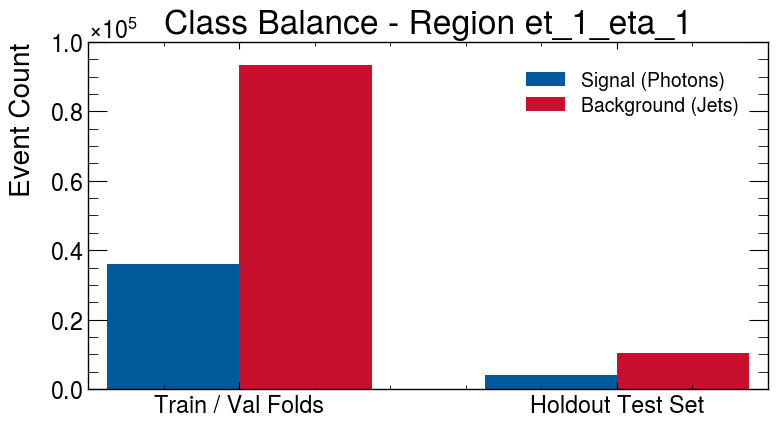

In [9]:
with open(CONFIG_PATH_1, "r") as f:
    config_dict_1 = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict_1["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config_1 = NeuralRingerTrainerConfiguration.model_validate(config_dict_1)
trainer_1 = NeuralRingerTrainer(config_1)
full_dataset = trainer_1.full_dataset

# Locate dataset index matching TARGET_ET and TARGET_ETA
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching et={TARGET_ET}, eta={TARGET_ETA} in {DATA_PATH}")

raw_features, raw_labels, region_file_path = full_dataset[region_file_idx]
print(f"Loaded dataset file: {region_file_path}")
print(f"Total events in region: {len(raw_labels):,}")

# Load test split indices from manifest
manifest = SplitManifest(str(MANIFEST_PATH))
if not manifest.exists():
    raise FileNotFoundError(f"Manifest not found at {MANIFEST_PATH}")

manifest.load()
test_indices, train_folds = manifest.get_region_splits(REGION_KEY)
test_indices = np.array(test_indices, dtype=int)

all_indices = np.arange(len(raw_labels))
train_val_mask = ~np.isin(all_indices, test_indices)
test_mask = np.isin(all_indices, test_indices)

test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]
train_val_labels = raw_labels[train_val_mask]

# Compute class counts
test_sig = int(np.sum(test_labels == 1))
test_bg = int(np.sum(test_labels == 0))
total_test = len(test_labels)

train_sig = int(np.sum(train_val_labels == 1))
train_bg = int(np.sum(train_val_labels == 0))
total_train = len(train_val_labels)

summary_df = pd.DataFrame([
    {
        "Partition": "Holdout Test Set",
        "Signal (Photons)": test_sig,
        "Background (Jets)": test_bg,
        "Total Events": total_test,
        "Signal Fraction": f"{test_sig / total_test:.2%}",
        "Background Fraction": f"{test_bg / total_test:.2%}",
    },
    {
        "Partition": "Train / Val Set",
        "Signal (Photons)": train_sig,
        "Background (Jets)": train_bg,
        "Total Events": total_train,
        "Signal Fraction": f"{train_sig / total_train:.2%}",
        "Background Fraction": f"{train_bg / total_train:.2%}",
    },
    {
        "Partition": "Full Region Data",
        "Signal (Photons)": test_sig + train_sig,
        "Background (Jets)": test_bg + train_bg,
        "Total Events": total_test + total_train,
        "Signal Fraction": f"{(test_sig + train_sig) / (total_test + total_train):.2%}",
        "Background Fraction": f"{(test_bg + train_bg) / (total_test + total_train):.2%}",
    }
])

display(summary_df)

# Plot class breakdown bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, [train_sig, test_sig], width, label="Signal (Photons)", color="#005A9C")
ax.bar(x + width/2, [train_bg, test_bg], width, label="Background (Jets)", color="#C8102E")
ax.set_xticks(x)
ax.set_xticklabels(["Train / Val Folds", "Holdout Test Set"])
ax.set_ylabel("Event Count")
ax.set_title(f"Class Balance - Region {REGION_KEY}")
ax.legend()
plt.tight_layout()
plt.show()


### 2. Feature Extraction & Distributions by Class Label
Defines the feature extractor (supporting raw columns and calculated variables like $E_{\text{ratio}} = (E_{\text{max1}} - E_{\text{max2}}) / (E_{\text{max1}} + E_{\text{max2}})$) and plots signal vs background histograms:



In [11]:
full_dataset.feature_names


array(['avgmu', 'ph_et', 'ph_eta', 'ph_phi', 'ph_Reta', 'ph_Rphi',
       'ph_e237', 'ph_e277', 'ph_Rhad', 'ph_Rhad1', 'ph_weta1',
       'ph_weta2', 'ph_f1', 'ph_f3', 'ph_f1core', 'ph_fracs1',
       'ph_f3core', 'ph_Eratio', 'ph_deltaE', 'ph_ethad', 'ph_wtots1',
       'ph_ethad1', 'ph_calo_eta', 'ph_calo_phi', 'ph_calo_et',
       'ph_calo_etaBE2', 'ph_calo_e', 'ph_hasCalo', 'ph_ptcone20',
       'ph_ptcone30', 'ph_ptcone40', 'ph_ptvarcone20', 'ph_ptvarcone30',
       'ph_ptvarcone40', 'ph_isIsoFixedLoose', 'ph_passCaloIso',
       'ph_tight', 'ph_medium', 'ph_loose', 'ph_nGoodVtx',
       'ph_nPileupPrimaryVtx', 'trig_L1_ph_eta', 'trig_L1_ph_phi',
       'trig_L1_ph_emClus', 'trig_L1_ph_roi_et', 'trig_L1_ph_emIso',
       'trig_L1_ph_hadCore', 'trig_L1_ph_tauClus', 'trig_L1eFex_ph_eta',
       'trig_L1eFex_ph_phi', 'trig_L1eFex_ph_roi_et',
       'trig_L1eFex_ph_wstot', 'trig_L1eFex_ph_reta',
       'trig_L1eFex_ph_rhad', 'trig_L2_calo_et', 'trig_L2_calo_eta',
       'trig_L2_calo_

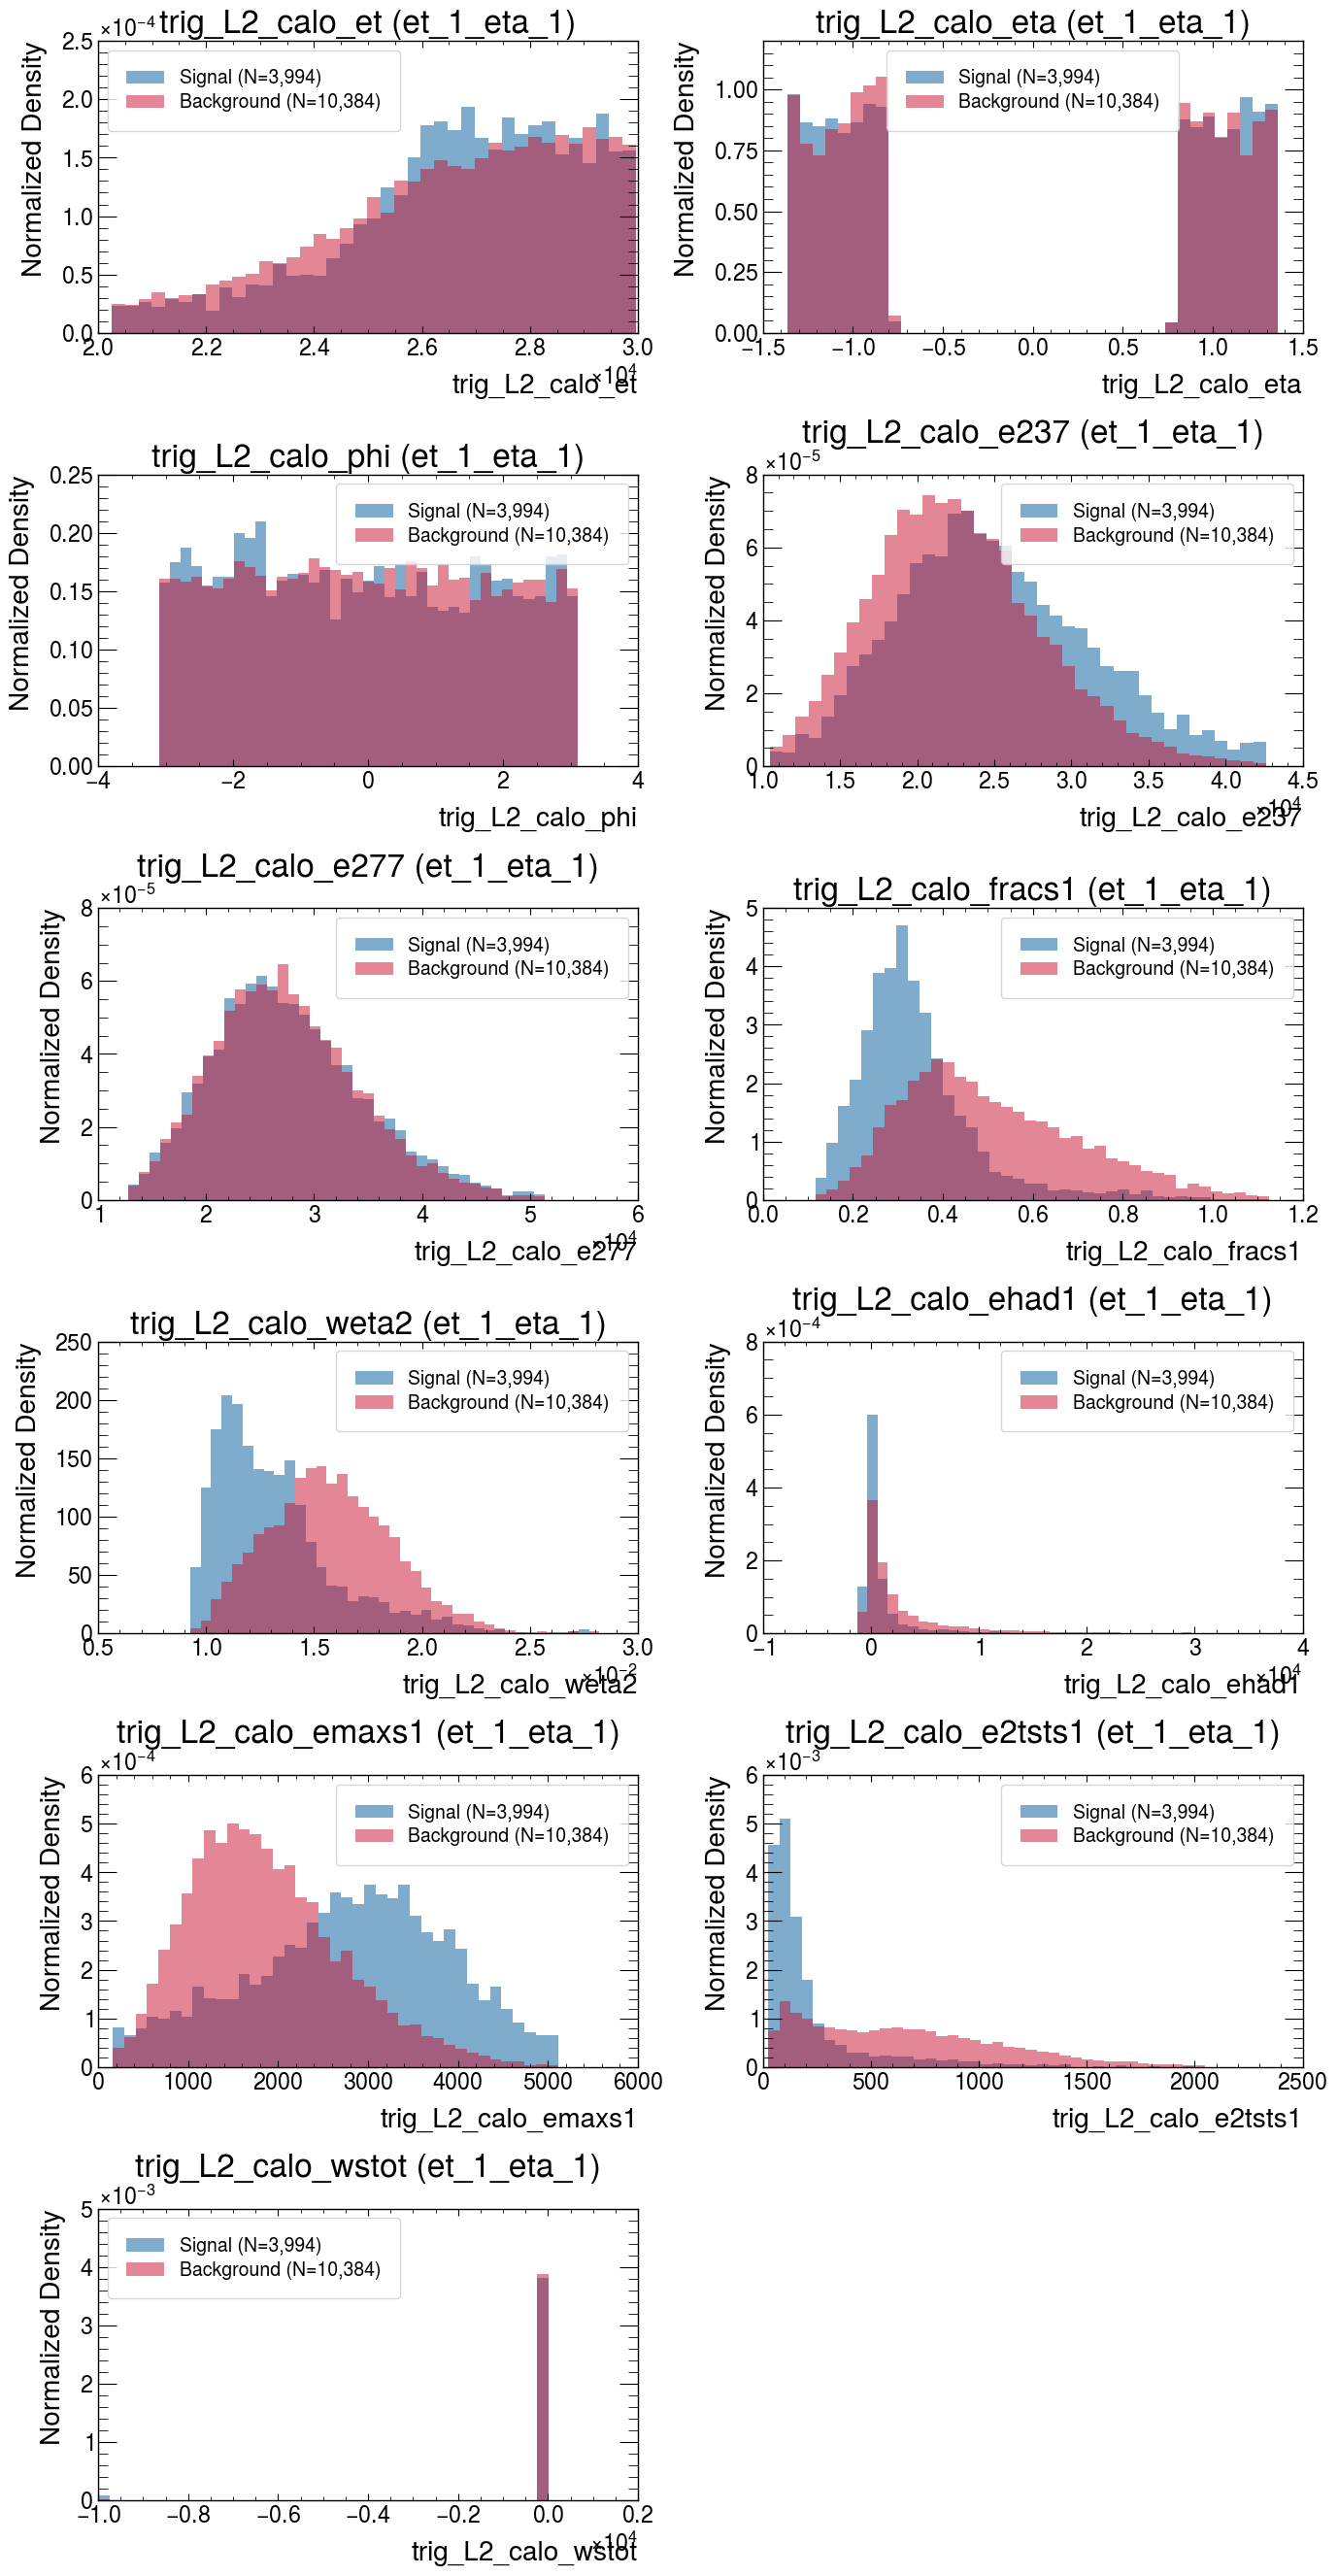

In [18]:
feature_names = full_dataset.feature_names

def extract_feature_values(
    features: np.ndarray,
    names: np.ndarray,
    feat_name: str,
) -> np.ndarray:
    """Extracts raw feature column or calculates derived physics variables like Eratio.
    
    Args:
        features: Event feature matrix of shape (N, D).
        names: Column feature names array of shape (D,).
        feat_name: Target variable name.
        
    Returns:
        1D numpy array of values.
    """
    name_to_idx = {name: i for i, name in enumerate(names)}
    
    if feat_name.lower() in ["eratio", "eration", "l2_eratio"]:
        if "trig_L2_calo_emaxs1" in name_to_idx and "trig_L2_calo_e2tsts1" in name_to_idx:
            emaxs1 = features[:, name_to_idx["trig_L2_calo_emaxs1"]]
            e2tsts1 = features[:, name_to_idx["trig_L2_calo_e2tsts1"]]
            denom = emaxs1 + e2tsts1
            safe_denom = np.where(denom != 0.0, denom, 1.0)
            return np.where(denom != 0.0, (emaxs1 - e2tsts1) / safe_denom, 0.0)
        elif "ph_Eratio" in name_to_idx:
            return features[:, name_to_idx["ph_Eratio"]]
        raise KeyError("Cannot compute Eratio: 'trig_L2_calo_emaxs1' and 'trig_L2_calo_e2tsts1' not found.")
        
    if feat_name in name_to_idx:
        return features[:, name_to_idx[feat_name]]
        
    raise KeyError(f"Feature '{feat_name}' not found in dataset columns.")

# Validate configured features
valid_features_to_plot = []
for f in FEATURES_TO_PLOT:
    try:
        _ = extract_feature_values(test_features[:5], feature_names, f)
        valid_features_to_plot.append(f)
    except KeyError as e:
        print(f"Skipping {f}: {e}")

n_features = len(valid_features_to_plot)
cols = 2
rows = (n_features + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, 4.2 * rows))
axes = np.array(axes).reshape(-1)
density = True
for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes[idx]
    col_idx = np.where(feature_names == feat_name)[0][0]

    val_sig = test_features[test_labels == 1, col_idx]
    val_bg = test_features[test_labels == 0, col_idx]

    # Clean non-finite entries if any
    val_sig = val_sig[np.isfinite(val_sig)]
    val_bg = val_bg[np.isfinite(val_bg)]

    # Automatic 1st to 99th percentile limits to avoid extreme outliers
    all_vals = np.concatenate([val_sig, val_bg])
    low, high = np.percentile(all_vals, 0.5), np.percentile(all_vals, 99.5)
    bins = np.linspace(low, high, 40)

    ax.hist(val_sig, bins=bins, density=density, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax.hist(val_bg, bins=bins, density=density, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")
    ax.set_title(f"{feat_name} ({REGION_KEY})")
    ax.set_xlabel(feat_name)
    ax.set_ylabel("Normalized Density")
    ax.legend(frameon=True)

# Remove unused subplots if odd number
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### 3. Model 1 Training Curves & Metric Evaluation
Scans fold files using [`ResultAggregator`](file:///home/pmourafr/egamma_master/src/core/Validation/ResultAggregator.py), extracts best SP checkpoint, and generates metric plots:



In [36]:
history_1.keys()

dict_keys(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'callbackMetrics', 'reapet'])

In [37]:
metrics_out_dir = OUTPUT_DIR / "Metrics_Model1"
metrics_out_dir.mkdir(parents=True, exist_ok=True)

aggregator_1 = ResultAggregator(RESULTS_PATH_1)
if not aggregator_1.has_region(TARGET_ET, TARGET_ETA):
    raise RuntimeError(f"No result records found in {RESULTS_PATH_1} for iet{TARGET_ET}.ieta{TARGET_ETA}")

best_model_1, best_rep_1, mean_sp_1, std_sp_1 = aggregator_1.get_best_model_for_region(TARGET_ET, TARGET_ETA)
print(f"Model 1 Best SP for {REGION_KEY}: {best_model_1['best_sp_value']:.4f} (Region Mean: {mean_sp_1:.4f} ± {std_sp_1:.4f})")
print(f"Best Fold: {best_model_1.get('fold')}, Best Init: {best_rep_1}")

# Generate training curves via PlotManager
plot_manager = PlotManager()
grouped_results_1 = aggregator_1.group_and_concat()
region_group_key = f"iet{TARGET_ET}.ieta{TARGET_ETA}"
df_region_1 = grouped_results_1.get(region_group_key)

if df_region_1 is not None and not df_region_1.empty:
    plot_manager.run_metrics_for_region(df_region_1, str(metrics_out_dir), TARGET_ET, TARGET_ETA)
    print(f"Generated metric figures saved under: {metrics_out_dir}")

Model 1 Best SP for et_1_eta_1: 0.8483 (Region Mean: 0.8445 ± 0.0035)
Best Fold: 6, Best Init: 1
Generated metric figures saved under: /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation/Metrics_Model1


### 4. Model 1 Efficiency Validation & Operational Response Curves
Evaluates the best checkpoint weights on the holdout test set using [`HoldoutEvaluator`](file:///home/pmourafr/egamma_master/src/core/Validation/HoldoutEvaluator.py) and [`EfficiencyPlotter`](file:///home/pmourafr/egamma_master/src/core/Validation/EfficiencyPlotter.py):



In [ ]:
validation_out_dir = OUTPUT_DIR / "Validation_Model1"
validation_out_dir.mkdir(parents=True, exist_ok=True)

model_1 = trainer_1.factory.create_model()
model_1.load_state_dict(best_model_1["best_weights"])
model_1.to(trainer_1.device)
model_1.eval()

evaluator = HoldoutEvaluator(default_target_pd=TARGET_PD)

ring_column_indices = full_dataset.ring_column_indices
if ring_column_indices is None:
    ring_column_indices = full_dataset.indexes

eval_result_1 = evaluator.evaluate(
    model=model_1,
    data=raw_features,
    target=raw_labels,
    test_indices=test_indices,
    ring_column_indices=ring_column_indices,
    device=trainer_1.device,
    target_pd=TARGET_PD,
)

print(f"Validation Holdout Performance for Model 1 ({REGION_KEY}):")
print(f"  Target Detection Efficiency (PD): {eval_result_1.pd:.4f}")
print(f"  Calibrated Operating Cut (Th):     {eval_result_1.threshold:.4f}")
print(f"  False Alarm Rate (PF):             {eval_result_1.pf:.4f}")
print(f"  SP Index at Target Cut:            {eval_result_1.sp:.4f}")
print(f"  Area Under ROC Curve (AUC):        {eval_result_1.auc:.4f}")

# Render efficiency curves
eta_idx = int(np.where(feature_names == "trig_L2_calo_eta")[0][0])
et_idx = int(np.where(feature_names == "trig_L2_calo_et")[0][0])
eff_plotter = EfficiencyPlotter(et_idx, eta_idx)

eff_plotter.plot_regional_efficiency(
    result=eval_result_1,
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    plot_dir=validation_out_dir,
    config_name=config_1.config_name,
)
print(f"Efficiency validation plots saved to: {validation_out_dir}")


### 5. Quadrant Analysis: Model 1 vs Athena Trigger Linear Cuts
Compares predictions against the cut-based baseline using [`QuadrantAnalyzer`](file:///home/pmourafr/egamma_master/src/core/Validation/QuadrantAnalyzer.py) in `model_vs_cut` mode:



In [ ]:
quadrant_cut_dir = OUTPUT_DIR / "Quadrant_Model_vs_Cut"
quadrant_cut_dir.mkdir(parents=True, exist_ok=True)

quadrant_cut_analyzer = QuadrantAnalyzer(
    config_path1=str(CONFIG_PATH_1),
    data_path1=str(RESULTS_PATH_1),
    manifest_path=str(MANIFEST_PATH),
    threshold_mode=THRESHOLD_MODE,
    efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
    default_target_pd=TARGET_PD,
    mode="model_vs_cut",
    working_point=WORKING_POINT,
    target_et=TARGET_ET,
    target_eta=TARGET_ETA,
)

cut_results = quadrant_cut_analyzer.run()
if not cut_results:
    raise RuntimeError(f"No quadrant results generated for {REGION_KEY}")

cut_res = cut_results[0]
s1 = cut_res.metrics_strategy1
s2 = cut_res.metrics_strategy2
qm = cut_res.overall_metrics

comparison_table = pd.DataFrame([
    {
        "Strategy": cut_res.strategy1_name,
        "PD (Signal Eff)": f"{s1.pd:.2%}",
        "PF (Fake Rate)": f"{s1.pf:.2%}",
        "SP Index": f"{s1.sp:.4f}",
        "Accuracy": f"{s1.eff:.2%}",
    },
    {
        "Strategy": cut_res.strategy2_name,
        "PD (Signal Eff)": f"{s2.pd:.2%}",
        "PF (Fake Rate)": f"{s2.pf:.2%}",
        "SP Index": f"{s2.sp:.4f}",
        "Accuracy": f"{s2.eff:.2%}",
    }
])
display(comparison_table)

quadrant_counts = pd.DataFrame({
    "Quadrant": [
        "Both Correct",
        f"Only {cut_res.strategy1_name} Correct",
        f"Only {cut_res.strategy2_name} Correct",
        "Both Wrong"
    ],
    "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
    "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
})
print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
display(quadrant_counts)

# Render standard quadrant figures
quadrant_plotter = QuadrantPlotter()
saved_cut_plots = quadrant_plotter.plot([cut_res], quadrant_cut_dir, file_format=PLOT_FORMAT)
print(f"Generated {sum(len(p) for p in saved_cut_plots.values())} quadrant plots under: {quadrant_cut_dir}")


### 6. Feature Distributions with Selected Events (Black Dots Overlay)
Overlays the events accepted by the ML Model and Linear Cut on top of the signal and background test distributions:
- **Blue & Red filled histograms**: Ground truth test distributions (Signal = Photons, Background = Jets).
- **Black dots (`fmt='o'`) with error bars**: Observed event rate passed/accepted by the model in that bin.



In [ ]:
preds_model1 = cut_res.preds_strategy1
preds_cut = cut_res.preds_strategy2

fig, axes = plt.subplots(len(valid_features_to_plot), 2, figsize=(16, 4.5 * len(valid_features_to_plot)))
if len(valid_features_to_plot) == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, feat_name in enumerate(valid_features_to_plot):
    values = extract_feature_values(test_features, feature_names, feat_name)
    
    val_sig = values[test_labels == 1]
    val_bg = values[test_labels == 0]
    
    val_sig = val_sig[np.isfinite(val_sig)]
    val_bg = val_bg[np.isfinite(val_bg)]
    
    all_vals = np.concatenate([val_sig, val_bg])
    low = np.percentile(all_vals, 0.5)
    high = np.percentile(all_vals, 99.5)
    bins = np.linspace(low, high, 35)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    # Model 1 passed events
    val_m1_pass = values[preds_model1 == 1]
    val_m1_pass = val_m1_pass[np.isfinite(val_m1_pass)]
    counts_m1, _ = np.histogram(val_m1_pass, bins=bins)
    err_m1 = np.sqrt(counts_m1)

    # Linear Cut passed events
    val_cut_pass = values[preds_cut == 1]
    val_cut_pass = val_cut_pass[np.isfinite(val_cut_pass)]
    counts_cut, _ = np.histogram(val_cut_pass, bins=bins)
    err_cut = np.sqrt(counts_cut)
    
    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    
    # --- Column 0: ML Model ---
    ax_ml = axes[idx, 0]
    ax_ml.hist(val_sig, bins=bins, color="#005A9C", alpha=0.35, label=f"True Signal (N={len(val_sig):,})")
    ax_ml.hist(val_bg, bins=bins, color="#C8102E", alpha=0.35, label=f"True Background (N={len(val_bg):,})")
    ax_ml.errorbar(
        bin_centers, counts_m1, yerr=err_m1,
        fmt="o", color="black", markersize=4, capsize=2,
        label=f"ML Accepted (N={len(val_m1_pass):,})"
    )
    ax_ml.set_title(f"{display_title} - {cut_res.strategy1_name}")
    ax_ml.set_xlabel(display_title)
    ax_ml.set_ylabel("Events / Bin")
    ax_ml.legend(frameon=True)

    # --- Column 1: Athena Linear Cut ---
    ax_cut = axes[idx, 1]
    ax_cut.hist(val_sig, bins=bins, color="#005A9C", alpha=0.35, label=f"True Signal (N={len(val_sig):,})")
    ax_cut.hist(val_bg, bins=bins, color="#C8102E", alpha=0.35, label=f"True Background (N={len(val_bg):,})")
    ax_cut.errorbar(
        bin_centers, counts_cut, yerr=err_cut,
        fmt="o", color="black", markersize=4, capsize=2,
        label=f"Cut Accepted (N={len(val_cut_pass):,})"
    )
    ax_cut.set_title(f"{display_title} - {cut_res.strategy2_name}")
    ax_cut.set_xlabel(display_title)
    ax_cut.set_ylabel("Events / Bin")
    ax_cut.legend(frameon=True)

plt.tight_layout()
plt.show()


### 7. Comparative Quadrant Analysis: Model 1 vs Model 2
Loads a secondary model configuration and executes holdout quadrant benchmarking across both neural architectures:



In [ ]:
if not ENABLE_MODEL2_COMPARISON:
    print("Secondary model comparison skipped (ENABLE_MODEL2_COMPARISON is False).")
else:
    quadrant_m2m_dir = OUTPUT_DIR / "Quadrant_Model_vs_Model"
    quadrant_m2m_dir.mkdir(parents=True, exist_ok=True)

    quadrant_m2m_analyzer = QuadrantAnalyzer(
        config_path1=str(CONFIG_PATH_1),
        data_path1=str(RESULTS_PATH_1),
        config_path2=str(CONFIG_PATH_2),
        data_path2=str(RESULTS_PATH_2),
        manifest_path=str(MANIFEST_PATH),
        threshold_mode=THRESHOLD_MODE,
        efficiencies_csv=str(EFFICIENCIES_CSV) if EFFICIENCIES_CSV else None,
        default_target_pd=TARGET_PD,
        mode="model_vs_model",
        target_et=TARGET_ET,
        target_eta=TARGET_ETA,
    )

    m2m_results = quadrant_m2m_analyzer.run()
    if not m2m_results:
        print(f"No comparative results generated for Model 1 vs Model 2 in {REGION_KEY}")
    else:
        m2m_res = m2m_results[0]
        s1 = m2m_res.metrics_strategy1
        s2 = m2m_res.metrics_strategy2
        qm = m2m_res.overall_metrics

        m2m_table = pd.DataFrame([
            {
                "Model": m2m_res.strategy1_name,
                "PD (Signal Eff)": f"{s1.pd:.2%}",
                "PF (Fake Rate)": f"{s1.pf:.2%}",
                "SP Index": f"{s1.sp:.4f}",
                "Accuracy": f"{s1.eff:.2%}",
            },
            {
                "Model": m2m_res.strategy2_name,
                "PD (Signal Eff)": f"{s2.pd:.2%}",
                "PF (Fake Rate)": f"{s2.pf:.2%}",
                "SP Index": f"{s2.sp:.4f}",
                "Accuracy": f"{s2.eff:.2%}",
            }
        ])
        display(m2m_table)

        m2m_quadrant_counts = pd.DataFrame({
            "Quadrant": [
                "Both Correct",
                f"Only {m2m_res.strategy1_name} Correct",
                f"Only {m2m_res.strategy2_name} Correct",
                "Both Wrong"
            ],
            "Event Count": [qm.both_correct, qm.model1_only_correct, qm.model2_only_correct, qm.both_wrong],
            "Ratio": [f"{qm.both_correct_ratio:.2%}", f"{qm.model1_only_correct_ratio:.2%}", f"{qm.model2_only_correct_ratio:.2%}", f"{qm.both_wrong_ratio:.2%}"]
        })
        print(f"McNemar p-value: {qm.mcnemar_p_value:.3e}")
        display(m2m_quadrant_counts)

        # Save plots
        saved_m2m_plots = quadrant_plotter.plot([m2m_res], quadrant_m2m_dir, file_format=PLOT_FORMAT)
        print(f"Generated {sum(len(p) for p in saved_m2m_plots.values())} plots under: {quadrant_m2m_dir}")
